In [1]:
# --- VaccineScout configuration -------------------------------------------
# Makes scripts/ importable regardless of where the kernel was started, then
# loads every path and parameter from config.yaml at the repository root.
import sys
from pathlib import Path

_SCRIPTS_DIR = Path.cwd() if (Path.cwd() / "config_loader.py").is_file() else Path.cwd() / "scripts"
_SCRIPTS_DIR = _SCRIPTS_DIR.resolve()
if str(_SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(_SCRIPTS_DIR))

from config_loader import load_config

cfg = load_config()
print(f"Loaded config from {cfg.config_path}")

import pandas as pd
import matplotlib.pyplot as plt
import pickle

# --- Custom imports ---
from Helpers import *   # Contains utility functions for data processing and plotting

# Configure matplotlib for consistent plots
plt.style.use("seaborn-v0_8-whitegrid")


Loaded config from /home/pgangwar@AD.UCSD.EDU/FutureCoV/config.yaml


In [2]:
def load_data(file_path):
    """
    Loads a two-column Parquet file and converts it back into a Python dictionary.
    """
    # 1. Read the Parquet file into a DataFrame
    df = pd.read_parquet(file_path)
    
    # 2. Zip the 'key' and 'value' columns together and convert to a dict
    return dict(zip(df['key'], df['value']))

In [3]:
# --- Load data files ---
ROOT_PATH = cfg.data_root_str
DATA_PATH = cfg.file("final_df")

final_df = pd.read_parquet(DATA_PATH)

parent_node = pd.read_csv(cfg.file("parent_node"), keep_default_na=False)

node_mut_data = pd.read_parquet(cfg.file("node_spike_branch"))

dates_df = pd.read_csv(cfg.file("chronumental_dates"), sep='\t')

ver = cfg.pyro_version

pyro_df = read_pickle(cfg.pyro_spike_pickle(ver))

In [4]:
# --- Preprocess Date Data ---
dates_df['predicted_date'] = pd.to_datetime(dates_df['predicted_date'])

dates_df['predicted_date'] = dates_df['predicted_date'].dt.date

dates_df['predicted_date'] = pd.to_datetime(dates_df['predicted_date'])

dates_df = dates_df.rename(columns={'strain': 'node_id'})

In [5]:
# --- Define cutoff date ---
cutoff_date = cfg.cutoff_date

# --- Split dataframe into circulating and future segments ---
# Window geometry comes from the `analysis:` block in config.yaml.
_, future_df = split_circulating_and_future(
    final_df,
    cutoff_date_str=cutoff_date,
    **cfg.split_kwargs()
)

# --- Define windows for slicing future data ---
disjoint_windows = cfg.disjoint_windows

# --- Perform slicing ---
disjoint_slices = slice_by_disjoint_windows(future_df, disjoint_windows)

# --- Removing sequences seen < 5 sequences in a window ---
future_slices = {}
min_tip_count = cfg.min_tip_count
for window, df in disjoint_slices.items():  
    # Get the exact occurrence count for every Sequence_ID
    seq_counts = df['Sequence_ID'].value_counts()
    
    # Identify which Sequence_IDs meet or exceed the min_tip_count
    valid_seq_ids = seq_counts[seq_counts >= min_tip_count].index
    
    # Filter the original DataFrame to keep only the valid Sequence_IDs
    filtered_df = df[df['Sequence_ID'].isin(valid_seq_ids)].copy()
    
    # Store the filtered DataFrame in the new dictionary
    future_slices[window] = filtered_df

# --- Summary output ---
print(f"Disjoint slices: {list(disjoint_slices.keys())}")
print(f"Total future slices stored: {len(future_slices)}")

Disjoint slices: ['6M_1', '6M_2']
Total future slices stored: 2


Processing Nodes around Cutoff Date

In [6]:
# --- Filter Nodes around cutoff date ---
filtered_df = dates_df[dates_df['predicted_date'] < cutoff_date]

filtered_df = filtered_df[filtered_df['node_id'].str.contains('node_')]

nodes_before_cutoff = set(filtered_df['node_id'])

In [7]:
# --- Create Lookup Dictionaries ---
parent_node_clean = parent_node.dropna().drop_duplicates(subset=["node"])

parent_lookup = dict(zip(parent_node_clean["node"], parent_node_clean["parent_node"]))

mutations_lookup = dict(zip(node_mut_data['sample_id'], node_mut_data['aa_mutations']))

fitness_lookup = dict(zip(pyro_df['mutation'], pyro_df['R / R_A']))

In [8]:
# --- Apply functions to future data ---
for key, df in future_slices.items():
    df = df.copy()

    # Existing computations
    df["node_path"] = df["Sample_ID"].apply(lambda x: build_node_path(x, parent_lookup))
    df["anchor_remainder"] = df["node_path"].apply(
        lambda path: find_anchor_remainder_reverse(path, nodes_before_cutoff)
    )
    remainder_muts = df["anchor_remainder"].apply(
        lambda ar: get_mutations_from_remainder(ar, mutations_lookup)
    )

    mut_lengths = remainder_muts.str.len()
    mask = mut_lengths > 0
    df = df[mask].copy()

    df["mutations_in_remainder"] = remainder_muts[mask]

    future_slices[key] = df

In [9]:
def get_fitness_list(mutation_list):
    # Score a missing entry as 1.0 (neutral), matching compute_fitness_score_pyro
    # in Helpers.py, which multiplies by score_dict.get(mut, 1.0). 
    return [fitness_lookup.get(mut, 1.0) for mut in mutation_list]

for key, df in future_slices.items():
    df['fitness_in_remainder'] = df['mutations_in_remainder'].apply(get_fitness_list)
    # .str.len() checks the length of the list in each row. We only keep lengths > 0.
    df = df[df['fitness_in_remainder'].str.len() > 0].copy()
    future_slices[key] = df


In [10]:
slice_stats = {}

for key, df in future_slices.items():

    all_mutations = [m for lst in df['mutations_in_remainder'] for m in lst]
    
    slice_stats[key] = {
        "total_mutations": len(all_mutations),
        "unique_mutations": len(set(all_mutations)),
        "total_sequences": len(df)  
    }

In [11]:
# --- Compute fitness frequency distributions ---
fitness_freqs = {}

for key, df in future_slices.items():
    # Flatten all fitness scores across tips seen after the cutoff
    all_fitness = [f for lst in df['fitness_in_remainder'] for f in lst if f is not None]
    
    # Count frequency of each score
    freq_df = pd.Series(all_fitness).value_counts().reset_index()
    freq_df.columns = ["fitness_score", "frequency"]
    
    # Store in dict
    fitness_freqs[key] = freq_df

fitness_freqs_normalized = {}

for key, freq_df in fitness_freqs.items():
    total_mutations = slice_stats[key]["total_mutations"]

    # add a normalized percentage column
    freq_df = freq_df.copy()
    freq_df["percent"] = (freq_df["frequency"] / total_mutations) * 100

    fitness_freqs_normalized[key] = freq_df

Process Mutation Counts

In [12]:
import numpy as np

# Expanded range to guarantee NO data is dropped before being caught by the corner bins
bin_edges = np.arange(0.0, 2.0 + 0.01, 0.0001)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

binned_results = {}

for key, df in fitness_freqs_normalized.items():
    # sum percent in each bin
    binned, _ = np.histogram(
        df["fitness_score"],
        bins=bin_edges,
        weights=df["percent"]  # sum of percentages
    )

    binned_results[key] = pd.DataFrame({
        "bin_center": bin_centers,
        "percent_sum": binned
    })

## Plot Mutation Prevalence

Here, a mutation is counted once per haplotype that carriesit, so a mutation 
on an internal node is repeated for every descendant tip in the window.

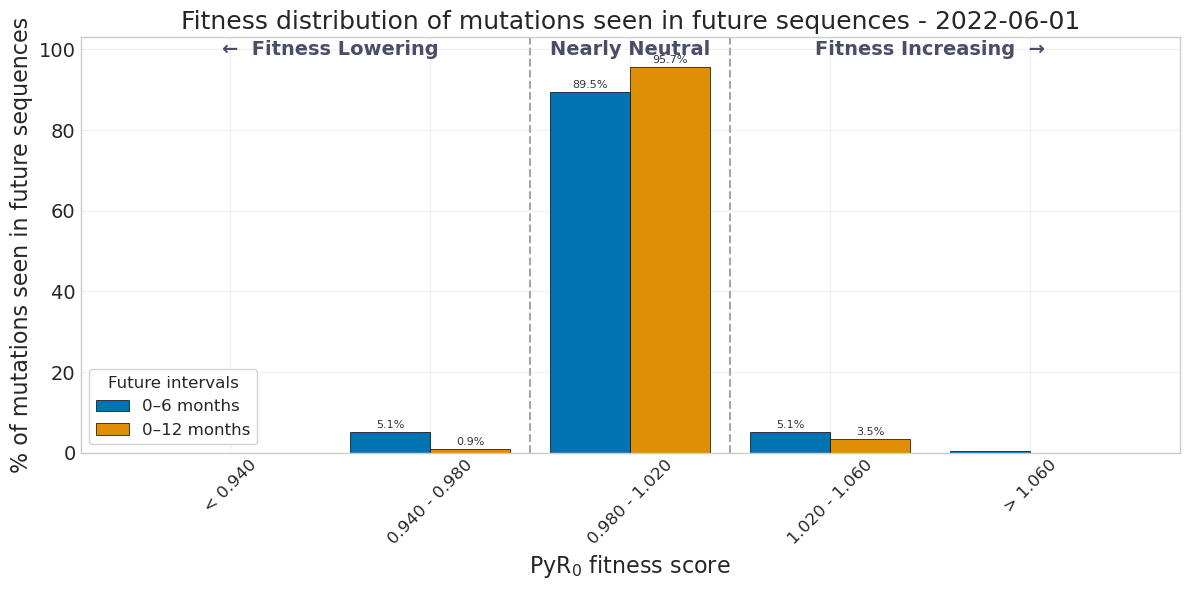

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

legend_labels = {
    "6M_1": "0–6 months",
    "6M_2": "0–12 months"
}

# seaborn colorblind palette
palette = sns.color_palette("colorblind", n_colors=len(disjoint_windows))
slice_colors = {key: palette[i] for i, key in enumerate(disjoint_windows)}


def plot_fitness_bands(binned_results, title, ylabel, out_path):
    """
    Body is the original plotting code; only the title, the y-axis label and
    the output path are parameters, so both figures share one implementation.
    """
    plt.figure(figsize=(12, 6))

    BAND_WIDTH = 0.040
    LOWER_LO, NEUTRAL_LO, NEUTRAL_HI, UPPER_HI = 0.940, 0.980, 1.020, 1.060

    total_slices = len(disjoint_windows)
    target_bin_size = BAND_WIDTH  # bar spacing matches the band width
    group_width = target_bin_size * 0.8
    bar_width = group_width / total_slices

    for i, key in enumerate(disjoint_windows):
        df = binned_results[key].copy()
    
        conditions = [
            df["bin_center"] < LOWER_LO,
            (df["bin_center"] >= LOWER_LO) & (df["bin_center"] < NEUTRAL_LO),
            (df["bin_center"] >= NEUTRAL_LO) & (df["bin_center"] < NEUTRAL_HI),
            (df["bin_center"] >= NEUTRAL_HI) & (df["bin_center"] < UPPER_HI),
            df["bin_center"] >= UPPER_HI
        ]

        # Visual x-coordinates, spaced one band width apart
        choices = [0.92, 0.96, 1.00, 1.04, 1.08]
        df["coarse_bin"] = np.select(conditions, choices)
    
        df_grouped = df.groupby("coarse_bin", as_index=False)["percent_sum"].sum()  
        x = df_grouped["coarse_bin"].to_numpy()
        y = df_grouped["percent_sum"].to_numpy()

        offset = (i - (total_slices - 1) / 2) * bar_width

        plt.bar(
            x + offset, y, 
            width=bar_width, 
            color=slice_colors[key], 
            label=legend_labels[key], 
            alpha=1.0,            
            edgecolor='black',   
            linewidth=0.5
        )

        for val_x, val_y in zip(x + offset, y):
            if val_y > 0.5:  
                plt.text(
                    val_x, val_y + 0.5,      
                    f"{val_y:.1f}%",        
                    ha='center', va='bottom', 
                    fontsize=8,                
                    rotation=0,              
                    color='#333333'            
                )

    plt.title(title, fontsize=18)

    plt.xlabel("PyR$_0$ fitness score", fontsize=16)
    plt.ylabel(ylabel, fontsize=16)
    leg = plt.legend(title="Future intervals", fontsize=12, title_fontsize=12, 
                     frameon=True, facecolor='white', edgecolor='lightgray', framealpha=1.0)
    leg.set_zorder(100)

    # x-limits sized to fit the 0.92 and 1.08 anchors
    plt.xlim(0.89, 1.11)

    # Set the new ticks and labels
    clean_ticks = [0.92, 0.96, 1.00, 1.04, 1.08]
    tick_labels = ["< 0.940", "0.940 - 0.980", "0.980 - 1.020", "1.020 - 1.060", "> 1.060"]

    plt.xticks(ticks=clean_ticks, labels=tick_labels, rotation=45, fontsize=12)
    plt.gca().ticklabel_format(axis='y', useOffset=False, style='plain')

    plt.yticks(fontsize=14)
    plt.grid(alpha=0.3)
    plt.ylim(0, 103)

    # Realign the vertical threshold lines to match the central bin boundaries
    plt.axvline(x=NEUTRAL_LO, color='gray', linestyle='--', linewidth=1.5, alpha=0.7, zorder=0)
    plt.axvline(x=NEUTRAL_HI, color='gray', linestyle='--', linewidth=1.5, alpha=0.7, zorder=0)

    # Re-center text annotations over the new groups
    plt.text(
        x=0.94, y=100, 
        s="←  Fitness Lowering", 
        ha='center', va='center', 
        fontsize=14, fontweight='bold', color='#4a4e69'
    )
    plt.text(
        x=1.00, y=100, 
        s="Nearly Neutral", 
        ha='center', va='center', 
        fontsize=14, fontweight='bold', color='#4a4e69'
    )
    plt.text(
        x=1.06, y=100, 
        s="Fitness Increasing  →", 
        ha='center', va='center', 
        fontsize=14, fontweight='bold', color='#4a4e69'
    )

    plt.tight_layout()
    plt.savefig(out_path, format='svg', bbox_inches='tight', dpi=300)
    plt.show()


# --- Plot 1: prevalence (a mutation counted once per tip carrying it) ---
plot_fitness_bands(
    binned_results,
    title=f'Fitness distribution of mutations seen in future sequences - {cutoff_date}',
    ylabel="% of mutations seen in future sequences",
    out_path=cfg.cutoff_dir(cutoff_date) / 'fitness.svg',
)


## Mutation Events
The block below counts *events*. Counting happens in the *Spike tree*: the MAT
projected onto Spike mutations only. A branch is identified by its whole Spike
path from the anchor, so two lineages that arrived by an identical Spike path 
count once between them however far apart they sit in the genome tree.

In [14]:
# --- Mutation events: the Spike-tree projection ---
from collections import defaultdict

# node -> Spike mutations on its incoming branch, mutation-bearing nodes only,
# so membership doubles as "does this branch carry anything".
branch_muts = {}
for _node, _raw in mutations_lookup.items():
    if not _raw:
        continue
    _toks = tuple(t.strip() for t in str(_raw).split(";") if t.strip())
    if _toks:
        branch_muts[_node] = _toks

print(f"{len(branch_muts):,} mutation-bearing branches in the tree")


def binned_from_mutations(mutations):
    """Fitness bins for a flat list of mutations, as in the two cells above."""
    fitness = get_fitness_list(mutations)
    freq_df = pd.Series(fitness).value_counts().reset_index()
    freq_df.columns = ["fitness_score", "frequency"]
    freq_df["percent"] = (freq_df["frequency"] / len(fitness)) * 100
    binned, _ = np.histogram(
        freq_df["fitness_score"], bins=bin_edges, weights=freq_df["percent"]
    )
    return pd.DataFrame({"bin_center": bin_centers, "percent_sum": binned})


event_binned = {}
event_stats = {}

for key, df in future_slices.items():
    # Key: the compressed anchor -> parent-of-leaf path, mutation-free nodes
    # dropped. Value: the distinct terminal mutation combinations under it.
    # The key is touched for every leaf, so a leaf with no terminal mutations
    # still registers its ancestry.
    table = defaultdict(set)
    for _anchor, remainder in df["anchor_remainder"]:
        bucket = table[tuple(n for n in remainder[:-1] if n in branch_muts)]
        leaf = remainder[-1]
        if leaf in branch_muts:
            bucket.add(canonical_mutations(branch_muts[leaf]))

    events, stats = accumulate_spike_events(table, branch_muts)

    event_stats[key] = {
        "internal_branches": stats["internal_branches"],
        "spike_paths": stats["distinct_spike_paths"],
        "events": len(events),
        "invariant_violations": stats["invariant_violations"],
    }
    event_binned[key] = binned_from_mutations(events)

for key, stats in event_stats.items():
    verdict = "OK" if stats["invariant_violations"] == 0 else "VIOLATIONS"
    print(
        f"{key}: {stats['events']:,} events "
        f"| {stats['spike_paths']:,} distinct Spike paths "
        f"| {stats['internal_branches']:,} internal branches "
        f"| invariant: {verdict}"
    )


1,079,545 mutation-bearing branches in the tree
6M_1: 9,345 events | 8,488 distinct Spike paths | 45,427 internal branches | invariant: OK
6M_2: 12,639 events | 11,835 distinct Spike paths | 31,387 internal branches | invariant: OK


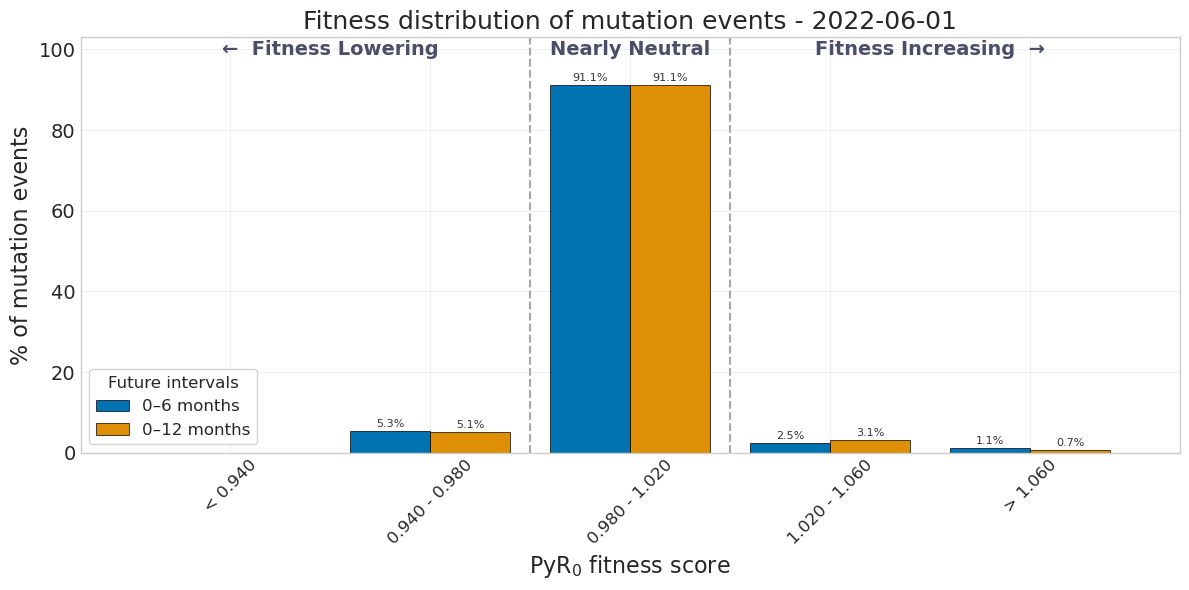

In [15]:
# --- Plot 2: mutation events (each branch counted once) ---
plot_fitness_bands(
    event_binned,
    title=f'Fitness distribution of mutation events - {cutoff_date}',
    ylabel="% of mutation events",
    out_path=cfg.cutoff_dir(cutoff_date) / 'fitness_events.svg',
)